# 8. Looped Reasoning with Flows

Every notebook so far used many network evaluations to **generate** data. This one uses them to **solve problems**: given a puzzle $c$, produce its unique solution $x$. The extra evaluations become extra *thinking time*.

There are two families of models that "think longer" at test time:

- **Looped models** (HRM, TRM) apply one network over and over to a hidden state, $z_i = f(z_{i-1}; c)$. More loops = more serial computation. They are hard to train: backpropagating through many loops is expensive and unstable, so training cuts the gradient between loops, and then nothing teaches early loops to set up later ones.
- **Flow models** also apply one network many times, but each step is trained with its own *local* denoising loss (notebooks 3b and 4). No backpropagation through time is needed, yet the steps add up to a coherent trajectory.

Three recent papers combine the two:

| Paper | Idea in one line |
|---|---|
| *One Step Forward and K Steps Back: Better Reasoning with Denoising Recursion Models* (Cameron et al., 2026, [arXiv:2604.18839](https://arxiv.org/abs/2604.18839)) | Corrupt the answer (one step forward along a diffusion process), then train a looped model to recover it in $k$ recursive steps (k steps back). |
| *Flow Reasoning Models: Scaling Reasoning Through Iterative Self-Refinement* (Helbling et al., 2026, [arXiv:2606.29150](https://arxiv.org/abs/2606.29150)) | A discrete flow that conditions on its own previous prediction; correct answers are stable fixed points, so stability can be used to pick answers. |
| *Thinking with Looped Flows* (Suleymanzade et al., 2026, [arXiv:2609.11801](https://arxiv.org/abs/2609.11801)) | Make the flow's denoiser *stateful* and train the recurrence on a sequence of denoising problems with decreasing noise and **shared** noise. |

We implement small versions of these ideas on **6×6 Sudoku**, train them on a CPU in a few minutes each, and study:

1. how accuracy scales with the number of inference steps (and what happens beyond the training horizon);
2. how accuracy depends on the **serial depth** a puzzle needs;
3. stochastic (SDE) integration;
4. fixed points, spurious attractors, and using stability as a verifier;
5. multiple valid solutions from different noise seeds;
6. the "shared-noise shortcut" and why it is not a problem.

The math is in THEORY.md §12; the physics view (reasoning as annealed relaxation) is in PHYSICS.md §11.8.

**Runtime:** about 20 minutes on an 8-core CPU (mostly training), much less on a GPU. All models are tiny (≈0.4M parameters), so absolute numbers are *not* comparable to the papers. The point is the mechanisms.

In [1]:
import math, os, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

device = torch.device("cuda") if torch.cuda.is_available() else torch.device("mps") if torch.backends.mps.is_available() else torch.device("cpu")
if device.type == "cpu":
    torch.set_num_threads(os.cpu_count())
print("device:", device)
plt.rcParams['font.size'] = 12

device: cpu


---
## 1. The task: 6×6 Sudoku, with a measurable "reasoning depth"

A 6×6 Sudoku has rows, columns and 2×3 boxes that must each contain 1–6. To make **serial reasoning** visible, we only use puzzles that can be solved by repeated rounds of the two simplest deductions:

- *naked single*: a cell with only one candidate value left;
- *hidden single*: a value that fits in only one cell of a row/column/box.

All deductions available in a round are applied in parallel, then the next round starts. The **depth** of a puzzle is the number of rounds needed. A depth-5 puzzle has cells whose value can only be known after 4 earlier rounds of deductions. That is a chain of computation that a fixed-size network cannot do in one shot, but a loop can.

In [2]:
N, BR, BC = 6, 2, 3                       # grid size, box rows, box cols
CELLS = N * N
rows, cols = np.arange(CELLS) // N, np.arange(CELLS) % N
boxes = (rows // BR) * (N // BC) + cols // BC
PEERS = [np.where(((rows == rows[i]) | (cols == cols[i]) | (boxes == boxes[i])) & (np.arange(CELLS) != i))[0] for i in range(CELLS)]
UNITS = [np.where(a == k)[0] for a in (rows, cols, boxes) for k in range(N)]
FULL = (1 << N) - 1

def candidates(g, i):
    # bitmask of values (bit v-1 = value v) that cell i can still take
    used = 0
    for j in PEERS[i]:
        if g[j]:
            used |= 1 << (g[j] - 1)
    return FULL & ~used

def solve(g, limit=2, rng=None, out=None):
    # count solutions (up to `limit`) by backtracking with the most-constrained cell first
    best, best_c, best_n = -1, 0, 99
    for i in range(CELLS):
        if g[i] == 0:
            c = candidates(g, i); n = bin(c).count('1')
            if n == 0: return 0
            if n < best_n: best, best_c, best_n = i, c, n
    if best < 0:
        if out is not None: out.append(list(g))
        return 1
    vals = [v + 1 for v in range(N) if best_c >> v & 1]
    if rng is not None: rng.shuffle(vals)
    total = 0
    for v in vals:
        g[best] = v
        total += solve(g, limit - total, rng, out)
        g[best] = 0
        if total >= limit: break
    return total

def random_grid(rng):
    out = []; solve([0] * CELLS, 1, rng, out); return out[0]

def propagation_depth(g):
    # rounds of parallel single-deductions needed to solve g; -1 if they get stuck
    g = list(g); depth = 0
    while 0 in g:
        new = {}
        for i in range(CELLS):
            if g[i] == 0:
                c = candidates(g, i)
                if bin(c).count('1') == 1: new[i] = c.bit_length()
        for u in UNITS:
            for v in range(1, N + 1):
                if any(g[j] == v for j in u): continue
                spots = [j for j in u if g[j] == 0 and candidates(g, j) >> (v - 1) & 1]
                if len(spots) == 1: new.setdefault(spots[0], v)
        if not new: return -1
        for i, v in new.items(): g[i] = v
        depth += 1
    return depth

def make_puzzle(rng):
    sol = random_grid(rng)
    n_blank = int(rng.integers(20, 25))
    while True:
        g = list(sol)
        for i in rng.permutation(CELLS)[:n_blank]: g[i] = 0
        d = propagation_depth(g)
        if d > 0: return np.array(g), np.array(sol), d   # d > 0 also implies a unique solution

def make_dataset(n, seed):
    rng = np.random.default_rng(seed)
    P = [make_puzzle(rng) for _ in range(n)]
    clues = torch.tensor(np.stack([p[0] for p in P]))          # 0 = blank, 1..6 = given
    sols = torch.tensor(np.stack([p[1] for p in P])) - 1       # 0..5
    depth = torch.tensor([p[2] for p in P])
    return clues, sols, depth

t0 = time.time()
N_TRAIN = 1000                         # small training set, as in the looped-model papers (Sudoku-Extreme uses 1000)
C_tr, S_tr, D_tr = make_dataset(N_TRAIN, seed=1)
C_te, S_te, D_te = make_dataset(1000, seed=2)
print(f"generated {N_TRAIN} train / 1000 test puzzles in {time.time() - t0:.0f}s")
print("test depth histogram:", {int(d): int((D_te == d).sum()) for d in D_te.unique()})

generated 1000 train / 1000 test puzzles in 18s
test depth histogram: {2: 222, 3: 443, 4: 260, 5: 60, 6: 14, 7: 1}


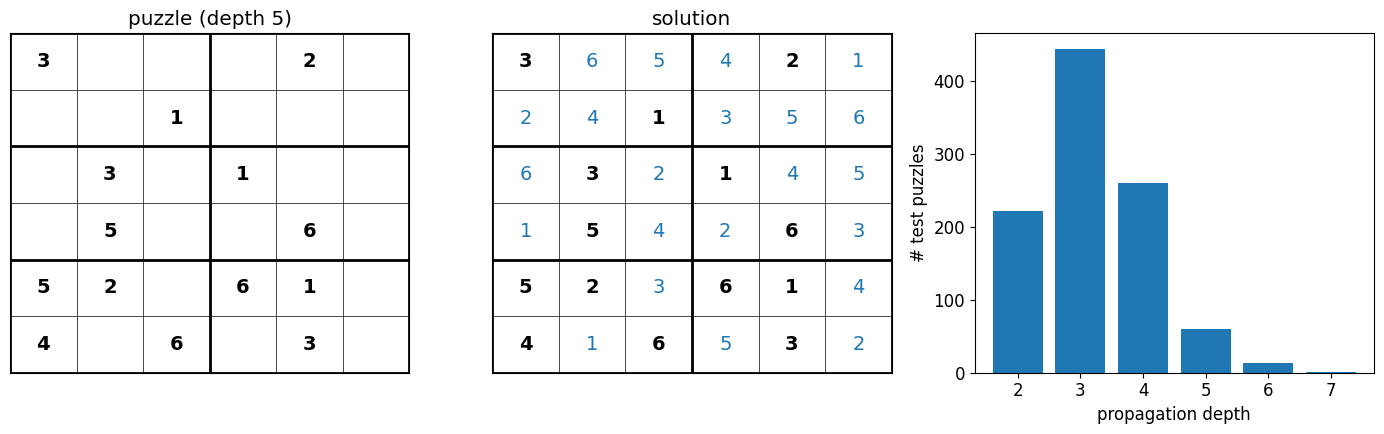

In [3]:
def show_grid(ax, clues, values=None, title=''):
    ax.set_xlim(0, N); ax.set_ylim(N, 0); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title)
    for k in range(N + 1):
        ax.axhline(k, color='k', lw=2 if k % BR == 0 else 0.5); ax.axvline(k, color='k', lw=2 if k % BC == 0 else 0.5)
    for i in range(CELLS):
        r, c = divmod(i, N)
        if clues[i] > 0:
            ax.text(c + .5, r + .5, str(int(clues[i])), ha='center', va='center', fontsize=14, weight='bold')
        elif values is not None:
            ax.text(c + .5, r + .5, str(int(values[i]) + 1), ha='center', va='center', fontsize=14, color='tab:blue')

i = int((D_te == 5).nonzero()[0])
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
show_grid(axes[0], C_te[i], title=f'puzzle (depth {int(D_te[i])})')
show_grid(axes[1], C_te[i], S_te[i], title='solution')
axes[2].bar(*np.unique(D_te.numpy(), return_counts=True)); axes[2].set_xlabel('propagation depth'); axes[2].set_ylabel('# test puzzles')
plt.tight_layout(); plt.show()

---
## 2. One small network for every method

All methods share the same **stateful denoiser**:

$$(\text{logits},\ z') = D(c,\ z,\ x_t,\ t)$$

- $c$: the clues, embedded per cell, plus **row, column and box embeddings**. Without these, a tiny model trained for a few minutes cannot even discover which cells constrain each other.
- $z$: a recurrent hidden state of shape (36 cells × 128 features). Methods without recurrence just pass zeros.
- $x_t$: an optional noisy, soft version of the answer (one probability vector per cell), and $t$ its noise level. Methods without a flow pass nothing.

Inside, a 2-layer transformer is applied twice ("cycles") to $z + \text{embeddings}$, so a single call does a small, fixed amount of computation. Any further reasoning must come from calling it again.

In [4]:
ROW, COL, BOX = (torch.tensor(a, device=device) for a in (rows, cols, boxes))
V = N                                       # 6 possible values per cell

class StatefulDenoiser(nn.Module):
    def __init__(self, d=128, layers=2, heads=4, cycles=2):
        super().__init__()
        self.d, self.cycles = d, cycles
        self.clue = nn.Embedding(V + 1, d)                      # 0 = blank
        self.row_e, self.col_e, self.box_e = nn.Embedding(N, d), nn.Embedding(N, d), nn.Embedding(N, d)
        self.x_proj = nn.Linear(V, d, bias=False)               # noisy answer x_t
        self.t_mlp = nn.Sequential(nn.Linear(1, d), nn.SiLU(), nn.Linear(d, d))
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, dropout=0.0, batch_first=True, norm_first=True)
        self.core = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.head = nn.Linear(d, V)

    def init_state(self, B):
        return torch.zeros(B, CELLS, self.d, device=device)

    def forward(self, clues, z, x=None, t=None):
        e = self.clue(clues) + self.row_e(ROW) + self.col_e(COL) + self.box_e(BOX)
        if x is not None: e = e + self.x_proj(x)
        if t is not None: e = e + self.t_mlp(t.view(-1, 1, 1))
        h = z
        for _ in range(self.cycles):
            h = self.core(h + e)
        return self.head(h), h

print(f"parameters: {sum(p.numel() for p in StatefulDenoiser().parameters()) / 1e6:.2f}M")

parameters: 0.42M


In [5]:
# small helpers shared by all methods
def onehot(s):
    return F.one_hot(s, V).float()

def clamp_clues(x, clues):
    # clue cells are known exactly: keep them at their one-hot value (the papers do the same)
    return torch.where((clues > 0).unsqueeze(-1), onehot((clues - 1).clamp(min=0)), x)

def blank_ce(logits, sol, clues):
    blank = clues == 0
    return F.cross_entropy(logits[blank], sol[blank])

SIGMA = 1 / math.sqrt(V)          # noise scale of x_0 ~ N(0, SIGMA^2 I), as in Looped Flows for categorical data

def interpolant(x0, x1, t, clues):
    # I_t = (1 - t) x0 + t x1, with t of shape (B,)
    tt = t.view(-1, 1, 1)
    return clamp_clues((1 - tt) * x0 + tt * x1, clues)

def batches(n_updates, B, seed):
    g = torch.Generator().manual_seed(seed)
    for _ in range(n_updates):
        idx = torch.randint(0, len(C_tr), (B,), generator=g)
        yield C_tr[idx].to(device), S_tr[idx].to(device)

---
## 3. Four training recipes

All four get the **same budget of 4800 forward+backward passes** of the network, on batches of 64 puzzles.

**(A) One-shot flow** (categorical flow matching, the "FLM" baseline). One denoising problem per update, no recurrent state:
$$\mathcal{L}_{\text{flow}} = \mathbb{E}_{t\sim U[0,1]}\,\text{CE}\big(D(c, 0, I_t, t),\ x_1\big), \qquad I_t = (1-t)x_0 + t x_1$$
The prediction $\hat x = \text{softmax}(\text{logits}) \approx \mathbb{E}[x_1 \mid I_t]$ is the $\hat x$-parameterization of 3b §4, and the sampling velocity is $b_t = (\hat x - x_t)/(1-t)$.

**(B) Looped model** (TRM-style truncated BPTT / deep supervision). Unroll $k = 8$ loops; every loop gets a loss; the gradient is cut between loops:
$$\mathcal{L}_{\text{loop}} = \textstyle\sum_{i} \text{CE}(\hat x_i, x),\qquad z_i = f(\text{sg}(z_{i-1}); c)$$

**(C) Looped flow** (Suleymanzade et al.). Unroll $k = 8$ loops along a **sequence of denoising problems**: times $t_0 < \dots < t_{k-1}$ are sorted uniforms (noise decreases), and one noise sample $x_0$ is **shared** by all loops. The gradient is still cut between loops:
$$\mathcal{L}_{\text{LF}} = \textstyle\sum_i \text{CE}(\hat x_{t_i}, x_1),\qquad (\hat x_{t_i}, z_{t_{i+1}}) = D\big(c,\ \text{sg}(z_{t_i}),\ I_{t_i},\ t_i\big)$$

**(D) Denoising recursion model** (Cameron et al.), "one step forward, $k$ steps back": mask a fraction $\sin^2(\pi\tau/2)$ of the answer cells (one step *forward* along the corruption process), then unroll $k = 4$ loops **with** gradients through all of them, and put the loss only at the end:
$$\mathcal{L}_{\text{DRM}} = \mathbb{E}_\tau\, \text{CE}\big(\hat x_k, x\big),\qquad z_i = f(z_{i-1};\, c, \tilde x_\tau)$$

In [6]:
B, LR = 64, 1e-3
PASSES = 4800                                   # forward+backward passes per method
K_LOOP, K_DRM = 8, 4

def new_model(seed=0):
    torch.manual_seed(seed)
    m = StatefulDenoiser().to(device)
    return m, torch.optim.AdamW(m.parameters(), lr=LR, weight_decay=0.1)

def train_flow():
    m, opt = new_model()
    for c, s in batches(PASSES, B, seed=1):
        x1 = onehot(s); t = torch.rand(len(c), device=device)
        x_t = interpolant(SIGMA * torch.randn_like(x1), x1, t, c)
        logits, _ = m(c, m.init_state(len(c)), x_t, t)
        loss = blank_ce(logits, s, c)
        opt.zero_grad(); loss.backward(); opt.step()
    return m

def train_loop():
    m, opt = new_model()
    for c, s in batches(PASSES // K_LOOP, B, seed=1):
        z = m.init_state(len(c))
        for i in range(K_LOOP):
            logits, z = m(c, z.detach())          # stop-gradient between loops
            loss = blank_ce(logits, s, c)
            opt.zero_grad(); loss.backward(); opt.step()
    return m

def train_looped_flow():
    m, opt = new_model()
    for c, s in batches(PASSES // K_LOOP, B, seed=1):
        x1 = onehot(s)
        x0 = SIGMA * torch.randn_like(x1)                                     # ONE noise sample, shared by all loops
        ts = torch.rand(len(c), K_LOOP, device=device).sort(dim=1).values     # increasing t = decreasing noise
        z = m.init_state(len(c))
        for i in range(K_LOOP):
            t = ts[:, i]
            logits, z = m(c, z.detach(), interpolant(x0, x1, t, c), t)
            loss = blank_ce(logits, s, c)
            opt.zero_grad(); loss.backward(); opt.step()
    return m

def mask_answer(s, clues, frac):
    # DRM corruption: hide a fraction `frac` (per puzzle) of the answer cells; hidden cells become all-zero vectors
    x = onehot(s)
    hide = torch.rand(s.shape, device=device) < frac.view(-1, 1)
    return clamp_clues(torch.where(hide.unsqueeze(-1), torch.zeros_like(x), x), clues)

def train_drm():
    m, opt = new_model()
    for c, s in batches(PASSES // K_DRM, B, seed=1):
        tau = torch.rand(len(c), device=device)
        x_tilde = mask_answer(s, c, torch.sin(math.pi * tau / 2) ** 2)          # one step forward
        z = m.init_state(len(c))
        for i in range(K_DRM):                                                 # k steps back, WITH gradients
            logits, z = m(c, z, x_tilde, tau)
        loss = blank_ce(logits, s, c)                                          # loss only at the end
        opt.zero_grad(); loss.backward(); opt.step()
    return m

models = {}
for name, fn in [('flow', train_flow), ('loop', train_loop), ('looped flow', train_looped_flow), ('DRM', train_drm)]:
    t0 = time.time(); models[name] = fn().eval()
    print(f"trained {name:12s} in {time.time() - t0:5.0f}s")

trained flow         in   155s


trained loop         in   152s


trained looped flow  in   155s


trained DRM          in   147s


---
## 4. Inference: how each model "thinks longer"

- **Flow**: integrate the flow on a grid of $n$ steps from $t=0$ (noise) to $t=1$, using the prediction $\hat x$ at each step (Euler: $x \leftarrow x + \Delta t\,(\hat x - x)/(1-t)$). The state is reset to zero every call.
- **Looped flow**: the same integration, but the hidden state $z$ is **carried** from step to step (Looped Flows Eq. 8).
- **Loop**: just call it $n$ times; there is no notion of "time", so more steps means running *past* its training horizon $k = 8$.
- **DRM**: start with every blank cell masked, take $n$ steps with decreasing $\tau$; at each step predict all cells, then re-mask a random subset of size $\sin^2(\pi\tau_{\text{next}}/2)$, carrying the state.

`run` returns the final prediction plus the per-step predictions and states, which we'll use later.

In [7]:
@torch.no_grad()
def run(model, kind, clues, n_steps, gamma=0.0, seed=0, keep=False):
    torch.manual_seed(seed)
    clues = clues.to(device); Bn = len(clues)
    z = model.init_state(Bn)
    preds, states = [], []
    if kind == 'loop':
        for _ in range(n_steps):
            logits, z = model(clues, z)
            if keep: preds.append(logits.softmax(-1).cpu()); states.append(z.cpu())
    elif kind == 'drm':
        taus = torch.linspace(1, 0, n_steps + 1, device=device)
        x = clamp_clues(torch.zeros(Bn, CELLS, V, device=device), clues)       # everything masked
        for i in range(n_steps):
            logits, z = model(clues, z, x, taus[i].expand(Bn))
            pred = logits.argmax(-1)
            x = mask_answer(pred, clues, (torch.sin(math.pi * taus[i + 1] / 2) ** 2).expand(Bn))
            if keep: preds.append(logits.softmax(-1).cpu()); states.append(z.cpu())
    else:   # 'flow' (stateless) or 'looped flow' (stateful); gamma > 0 = stochastic noise-backtracking sampler
        grid = torch.linspace(0, 1, n_steps + 1, device=device)
        x = clamp_clues(SIGMA * torch.randn(Bn, CELLS, V, device=device), clues)
        for i in range(n_steps):
            t, t_next = grid[i].item(), grid[i + 1].item()
            # Looped Flows Algorithm 2: step back to an earlier time s with fresh noise, then Euler-step to t_next
            a = min(1.0, max(0.0, 1 - gamma * (t_next - t)))
            s = a * t
            x_bar = clamp_clues(a * x + SIGMA * math.sqrt(max((1 - s) ** 2 - (a - s) ** 2, 0.0)) * torch.randn_like(x), clues)
            logits, z_new = model(clues, z if kind == 'looped flow' else model.init_state(Bn), x_bar, torch.full((Bn,), s, device=device))
            if kind == 'looped flow': z = z_new
            x_hat = clamp_clues(logits.softmax(-1), clues)
            x = clamp_clues(x_bar + (t_next - s) * (x_hat - x_bar) / (1 - s), clues)
            if keep: preds.append(logits.softmax(-1).cpu()); states.append(z_new.cpu())
    pred = logits.argmax(-1).cpu()
    return (pred, preds, states) if keep else pred

def solved(pred, clues=C_te, sols=S_te):
    blank = clues == 0
    return ((pred == sols) | ~blank).all(dim=1)

KIND = {'flow': 'flow', 'loop': 'loop', 'looped flow': 'looped flow', 'DRM': 'drm'}

### 4.1 Accuracy vs. number of inference steps

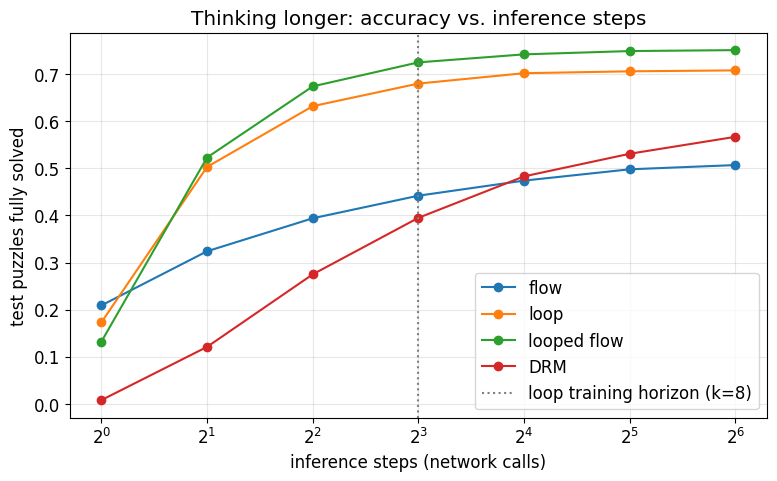

method            1      2      4      8     16     32     64   | train@16
flow          0.209  0.324  0.394  0.442  0.474  0.498  0.507   | 0.981
loop          0.173  0.503  0.632  0.680  0.702  0.706  0.708   | 0.989
looped flow   0.132  0.523  0.674  0.725  0.742  0.749  0.751   | 0.958
DRM           0.008  0.121  0.275  0.395  0.483  0.531  0.567   | 0.813


In [8]:
step_list = [1, 2, 4, 8, 16, 32, 64]
acc = {name: [solved(run(m, KIND[name], C_te, n)).float().mean().item() for n in step_list] for name, m in models.items()}
train_acc = {name: solved(run(m, KIND[name], C_tr, 16), C_tr, S_tr).float().mean().item() for name, m in models.items()}

plt.figure(figsize=(9, 5))
for name, a in acc.items():
    plt.plot(step_list, a, 'o-', label=name)
plt.axvline(K_LOOP, color='gray', ls=':', label='loop training horizon (k=8)')
plt.xscale('log', base=2); plt.xlabel('inference steps (network calls)'); plt.ylabel('test puzzles fully solved')
plt.title('Thinking longer: accuracy vs. inference steps'); plt.legend(); plt.grid(alpha=0.3); plt.show()

print(f"{'method':12s} " + " ".join(f"{n:>6d}" for n in step_list) + "   | train@16")
for name in models:
    print(f"{name:12s} " + " ".join(f"{a:6.3f}" for a in acc[name]) + f"   | {train_acc[name]:.3f}")

**What the run above shows** (your numbers may differ slightly on other hardware):

- **The plain flow memorizes.** It solves ~98% of *training* puzzles but only ~50% of test puzzles. This is the effect Looped Flows report for FLM in their Fig. 5: with 1000 training puzzles, local denoising alone overfits.
- **Recurrence generalizes better.** The looped model (~71%) and the looped flow (~75%) generalize much better at the same compute, and keep improving up to and beyond the 8 steps they were trained with.
- **One step is not enough for anyone.** At 1 step every model is poor, because a single call can't do several rounds of deduction. Most of the gain arrives in the first 4–8 calls.
- **DRM starts slowest but is still climbing at 64 steps.** It was trained with full backprop through a short 4-step window, so it gets fewer gradient updates for the same compute, and our masking sampler is the simplest possible. DRM's own paper finds it strongest on ARC-style tasks and weaker than TRM on Sudoku.
- **The loop can degrade past its horizon.** Nothing guarantees a looped model stays stable after its training horizon. In a variant run (4000 training puzzles, half the training budget) the loop peaked at 59% at 8 steps and then *dropped* to 39% at 64 steps, while the flow-based models plateaued. A flow has a built-in end point at $t = 1$, so more steps only means a finer grid.

### 4.2 Accuracy vs. required reasoning depth

Deeper puzzles need longer chains of deductions. Here every model gets its best step count from the sweep above.

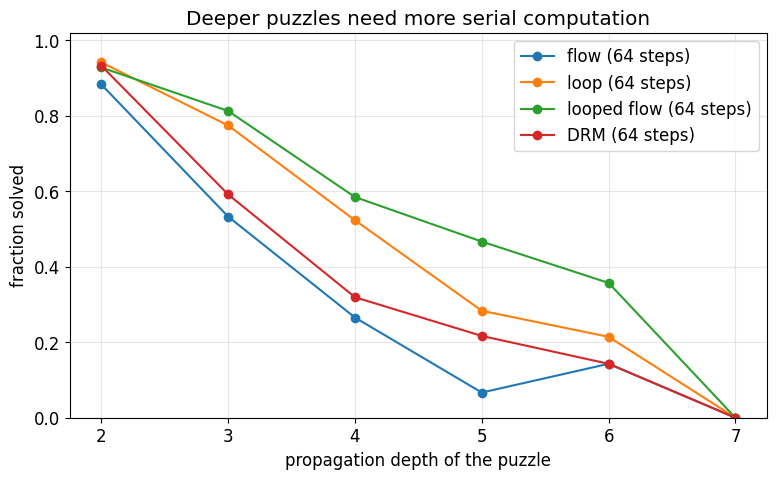

In [9]:
best_n = {name: step_list[int(np.argmax(a))] for name, a in acc.items()}
depths = sorted(D_te.unique().tolist())
plt.figure(figsize=(9, 5))
for name, m in models.items():
    ok = solved(run(m, KIND[name], C_te, best_n[name]))
    plt.plot(depths, [ok[D_te == d].float().mean().item() for d in depths], 'o-', label=f'{name} ({best_n[name]} steps)')
plt.xlabel('propagation depth of the puzzle'); plt.ylabel('fraction solved'); plt.ylim(0, 1.02)
plt.title('Deeper puzzles need more serial computation'); plt.legend(); plt.grid(alpha=0.3); plt.show()

---
## 5. Stochastic integration (noise backtracking)

The probability-flow ODE has the same marginals as a whole family of SDEs (0c §4.8, 3b §7). Looped Flows integrate one of them (THEORY.md §12.5):

$$dx_t = \big[(1+\gamma t)\,b_t(x_t) - \gamma x_t\big]dt + \sigma\sqrt{2\gamma(1-t)}\,dw_t$$

Their discrete version (implemented in `run` above) first moves the state **back** to an earlier time $s = a\,t_i$ by mixing in fresh noise, and then takes an Euler step forward. $\gamma = 0$ recovers the deterministic ODE. Injected noise lets the trajectory escape a bad early commitment, a little like annealing (PHYSICS.md §11.8).

In [10]:
for name in ['flow', 'looped flow']:
    row = []
    for gamma in [0.0, 1.0, 5.0]:
        accs = [solved(run(models[name], KIND[name], C_te, 32, gamma=gamma, seed=sd)).float().mean().item() for sd in range(3)]
        row.append(f"gamma={gamma}: {np.mean(accs):.3f} ± {np.std(accs):.3f}")
    print(f"{name:12s} (32 steps)  " + "   ".join(row))

flow         (32 steps)  gamma=0.0: 0.497 ± 0.001   gamma=1.0: 0.514 ± 0.004   gamma=5.0: 0.520 ± 0.002


looped flow  (32 steps)  gamma=0.0: 0.734 ± 0.013   gamma=1.0: 0.732 ± 0.010   gamma=5.0: 0.730 ± 0.008


Here stochastic integration gives the stateless flow a small boost (≈ +2 points) and is neutral for the looped flow. Looped Flows found $\gamma > 0$ helped modestly on most of their benchmarks (Table 4). The bigger payoff of noise is diversity (§7), not accuracy.

---
## 6. Fixed points, spurious attractors, and stability as a verifier

A looped model "thinks" by iterating until its state stops changing, i.e. it searches for a **fixed point**. Two things can go wrong (Looped Flows §5.1; Ren & Liu, 2026):

- **spurious attractor**: the iteration converges, but to a wrong answer;
- **non-convergence**: the state keeps moving.

Following Flow Reasoning Models, we measure how much the **prediction** changes from one step to the next: the symmetric KL divergence between consecutive predictive distributions, averaged over blank cells,
$$r_k = \tfrac{1}{|\text{blank}|}\textstyle\sum_{\text{cells}} \big(D_{KL}(p_k\|p_{k-1}) + D_{KL}(p_{k-1}\|p_k)\big).$$
We call a run *converged* if $r_k$ averaged over its last 8 steps is below $10^{-3}$ nats. (Looped Flows measure the change of the hidden *state* instead. In our tiny model the state's norm grows every call, because the transformer adds to its residual stream, so a relative state residual would shrink like $1/k$ for every puzzle and say nothing.)

Flow Reasoning Models turn this into a **verifier**: if correct answers are stable fixed points, a small residual should signal a correct answer. We check how well the final residual separates correct from incorrect answers (AUROC: 0.5 = useless, 1.0 = perfect).

loop        : solved 0.708 | converged & correct 0.704 | spurious attractor (converged, wrong) 0.265 | not converged 0.031 | AUROC(-residual -> correct) = 0.942


looped flow : solved 0.751 | converged & correct 0.749 | spurious attractor (converged, wrong) 0.238 | not converged 0.013 | AUROC(-residual -> correct) = 0.793


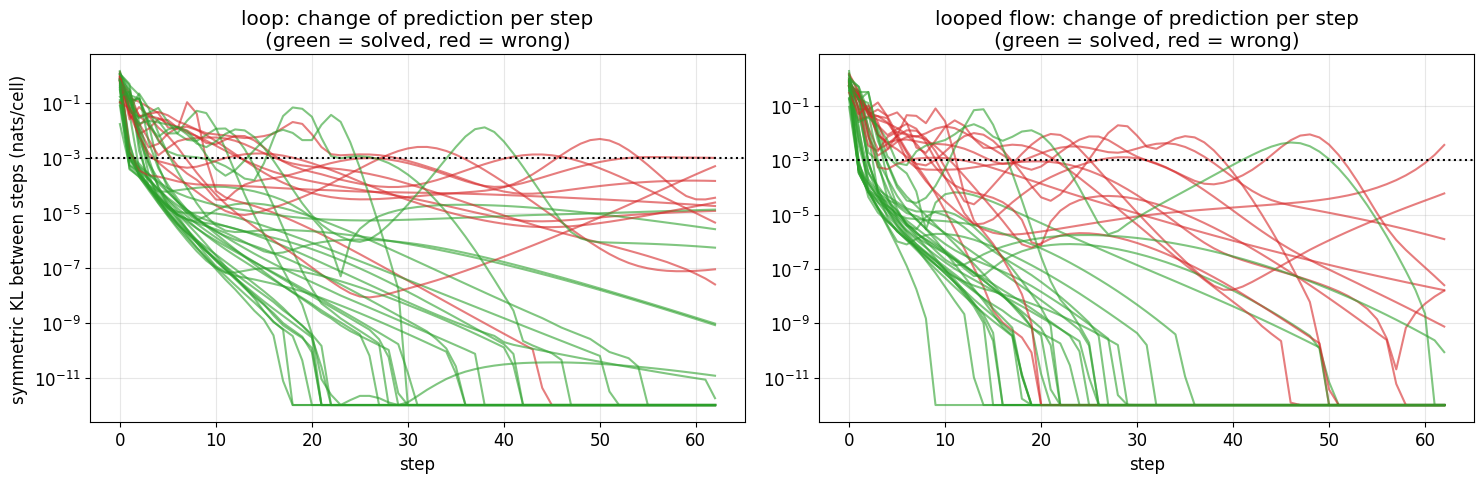

In [11]:
def auroc(score_pos, score_neg):
    # probability that a random positive gets a higher score than a random negative (ties count half)
    p, n = np.asarray(score_pos)[:, None], np.asarray(score_neg)[None, :]
    return ((p > n).mean() + 0.5 * (p == n).mean()) if len(p) and n.size else float('nan')

n_steps = 64
blank = (C_te == 0).float()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, name in zip(axes, ['loop', 'looped flow']):
    pred, preds, _ = run(models[name], KIND[name], C_te, n_steps, keep=True)
    P = torch.stack(preds).clamp(min=1e-8)                                     # (steps, B, cells, V)
    skl = ((P[1:] - P[:-1]) * (P[1:].log() - P[:-1].log())).sum(-1)           # symmetric KL per cell
    r = ((skl * blank).sum(-1) / blank.sum(-1)).numpy()                       # (steps-1, B)
    final_r = r[-8:].mean(0)
    converged = final_r < 1e-3
    ok = solved(pred).numpy()
    print(f"{name:12s}: solved {ok.mean():.3f} | converged & correct {(converged & ok).mean():.3f} | "
          f"spurious attractor (converged, wrong) {(converged & ~ok).mean():.3f} | not converged {(~converged).mean():.3f} | "
          f"AUROC(-residual -> correct) = {auroc(-final_r[ok], -final_r[~ok]):.3f}")
    for k in range(40):
        ax.semilogy(r[:, k] + 1e-12, color='tab:green' if ok[k] else 'tab:red', alpha=0.6)
    ax.axhline(1e-3, color='k', ls=':')
    ax.set_title(f'{name}: change of prediction per step\n(green = solved, red = wrong)'); ax.set_xlabel('step'); ax.grid(alpha=0.3)
axes[0].set_ylabel('symmetric KL between steps (nats/cell)')
plt.tight_layout(); plt.show()

**Reading the plot and numbers:**

- Almost every run **converges**: its prediction stops changing. But roughly a quarter converge to a **wrong** answer. Those are spurious attractors, the red curves that flatten out.
- Some wrong runs never quite settle (red curves hovering near the dotted line), and some correct runs take a detour before snapping into place.
- As a verifier, the final residual is useful but imperfect here: AUROC ≈ 0.94 for the loop and ≈ 0.8 for the looped flow. Neither model was trained to make the residual meaningful. That is exactly what FRM's Fixed-Point Forcing adds, raising their Sudoku-Extreme AUROC from 0.50 to 1.00.

A caveat that both papers stress: convergence certifies *stability*, not *correctness*. A deep wrong attractor looks exactly like a right one. Flow Reasoning Models show that how you train the carried state matters a lot here ("Fixed-Point Forcing": train on carries produced by the model's own closed-loop rollouts, not one-pass carries), and the residual only became a reliable verifier after that change.

---
## 7. Many valid answers from many noise seeds

A deterministic loop maps a puzzle to **one** answer. A flow starts from random noise, so different seeds can land on **different** valid solutions when a puzzle has several (Looped Flows Table 2: N-Queens and graph colouring). We remove more clues to create puzzles with 2–10 solutions, run 20 seeds each, and count how many distinct **valid** solutions each model finds.

(These models were trained only on unique-solution puzzles, so this is a test of out-of-distribution behaviour. The papers train on multi-solution data.)

In [12]:
def is_valid(grid, clues):
    # grid: (36,) values 0..5; check every unit has all values and clues are respected
    g = grid.numpy()
    if not all(len(set(g[u])) == N for u in UNITS): return False
    given = clues.numpy() > 0
    return bool((g[given] == clues.numpy()[given] - 1).all())

rng = np.random.default_rng(7)
multi = []
while len(multi) < 100:
    sol = random_grid(rng); g = list(sol)
    for i in rng.permutation(CELLS)[:26]: g[i] = 0
    n_sol = solve(list(g), limit=11)
    if 2 <= n_sol <= 10: multi.append((np.array(g), n_sol))
C_multi = torch.tensor(np.stack([m_[0] for m_ in multi])); n_sols = np.array([m_[1] for m_ in multi])
print(f"100 multi-solution puzzles, mean number of solutions {n_sols.mean():.1f}")

N_SEEDS = 20
for name, gamma in [('loop', 0.0), ('looped flow', 0.0), ('looped flow', 5.0), ('flow', 5.0)]:
    found = [set() for _ in range(len(multi))]; n_valid = 0
    for sd in range(N_SEEDS):
        pred = run(models[name], KIND[name], C_multi, 32, gamma=gamma, seed=sd)
        for k in range(len(multi)):
            if is_valid(pred[k], C_multi[k]):
                n_valid += 1; found[k].add(tuple(pred[k].tolist()))
    coverage = np.mean([len(f) / n for f, n in zip(found, n_sols)])
    print(f"{name:12s} gamma={gamma}: valid samples {n_valid / (N_SEEDS * len(multi)):.3f}   "
          f"coverage of all solutions {coverage:.3f}   mean distinct valid per puzzle {np.mean([len(f) for f in found]):.2f}")

100 multi-solution puzzles, mean number of solutions 6.6


loop         gamma=0.0: valid samples 0.300   coverage of all solutions 0.049   mean distinct valid per puzzle 0.30


looped flow  gamma=0.0: valid samples 0.245   coverage of all solutions 0.203   mean distinct valid per puzzle 1.31


looped flow  gamma=5.0: valid samples 0.244   coverage of all solutions 0.176   mean distinct valid per puzzle 1.16


flow         gamma=5.0: valid samples 0.089   coverage of all solutions 0.035   mean distinct valid per puzzle 0.20


**Reading the numbers:**

- The deterministic **loop** can return at most one answer per puzzle, so its coverage of all valid solutions is tiny (≈5%).
- The **looped flow**, run from different noise seeds, finds on average 1.3 distinct valid solutions per puzzle (≈20% coverage), even though it never saw a multi-solution puzzle in training.
- The stateless **flow** mostly produces invalid grids on these harder, out-of-distribution puzzles.

This is "probability transport" at work: the starting noise selects which solution the flow is carried to. Training on multi-solution data, as the paper does, would raise both validity and coverage.

---
## 8. The shared-noise shortcut (and why it's harmless)

Looped Flows share one noise sample $x_0$ across all training steps. Then two interpolants at times $s < t$ determine the answer exactly:

$$\frac{(1-s)\,I_t - (1-t)\,I_s}{t-s} = x_1$$

A recurrent state that simply *remembered* the previous input could cancel the noise and read off the answer during training, without reasoning. Let's check the identity numerically:

In [13]:
x1 = onehot(S_tr[:4]).to(device); x0 = SIGMA * torch.randn_like(x1)
s_, t_ = 0.2, 0.5
I_s, I_t = (1 - s_) * x0 + s_ * x1, (1 - t_) * x0 + t_ * x1
recovered = ((1 - s_) * I_t - (1 - t_) * I_s) / (t_ - s_)
print("max |recovered - x1| =", (recovered - x1).abs().max().item())

max |recovered - x1| = 2.384185791015625e-07


At **inference** the trick cannot help, because there is no true $x_1$ in the inputs. Applying it to the model's own Euler trajectory recovers only the model's *first* guess $\hat x_{t_0}$, so a model relying on it would never improve with more steps (Looped Flows App. B). Accuracy that keeps rising with more steps (§4.1) is evidence the model does not rely on the shortcut. Also, stop-gradients mean no loss ever teaches an earlier step to *store* its input for a later step to exploit.

---
## 9. Summary

| Method | State carried between calls | Training signal across calls | How it spends more test compute |
|---|---|---|---|
| Flow (FLM) | only $x_t$ | none: independent local losses | finer time grid |
| Loop (TRM-style) | latent $z$ | none: stop-gradient + per-step loss | more loops; can go unstable past the training horizon |
| Looped flow | latent $z$ **and** $x_t$ | none, but consecutive problems are aligned (sorted times, shared noise) | finer time grid, SDE noise, more seeds |
| DRM | latent $z$ | full BPTT through one $k$-step window, curriculum via corruption level | more denoising steps |
| FRM (not trained here) | previous prediction (self-conditioning) | detached carries from closed-loop rollouts ("Fixed-Point Forcing") | recurrence depth + flow steps; stability as a verifier |

Things to remember:

1. **Flows are already looped models**: their state is $x_t$, and their training is a set of local denoising problems that never needs backpropagation through time (3b, 0c). That is exactly what looped reasoners struggle with.
2. Adding a **hidden state** to the denoiser lets each step pass on partial work. **Aligning** consecutive training problems (decreasing noise, shared noise) is what makes that state useful.
3. A flow has a built-in end point ($t = 1$), so "think longer" means "integrate more finely", not "iterate past what you were trained for".
4. Stability is a cheap verifier, but convergence is not correctness.
5. Toy-scale caveats: the models are tiny and trained for minutes. Which method wins depends on data size, budget and task, and the rankings here need not match the papers. Rerun with `N_TRAIN`, `PASSES`, or the puzzle depth changed and see what moves.